# ANÁLISE DE DADOS DOS FILMES | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para dados dos filmes e se eles causam impacto na bilheteria.
___

### 0 | Importações
___

In [1]:
# Manipulação de dados:
import pandas as pd
import numpy as np             

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio

pio.renderers.default='png'

In [2]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### 1 | Mapa de calor geral:
___

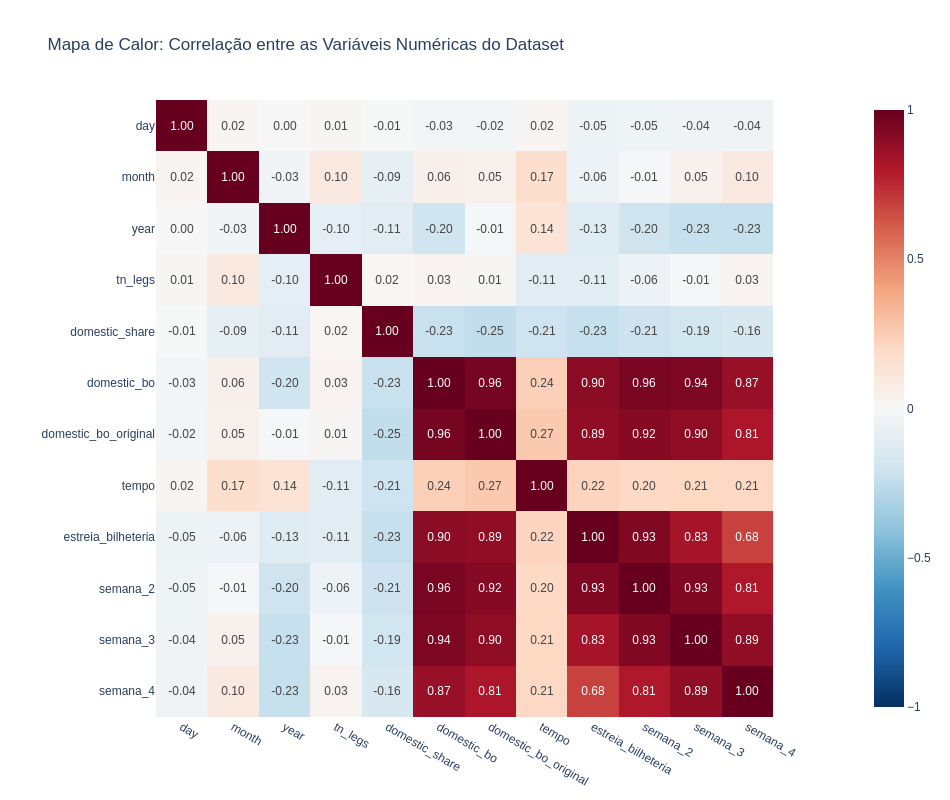

In [3]:
df_numerico = df.select_dtypes(include=[np.number])

# 3. Calcula a matriz de correlação de Pearson
matriz_corr = df_numerico.corr()

# 4. Gera o Heatmap interativo com Plotly
fig = px.imshow(
    matriz_corr,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1, zmax=1,
    title='Mapa de Calor: Correlação entre as Variáveis Numéricas do Dataset'
)

fig.update_layout(
    width=950,
    height=800,
    template='plotly_white'
)

fig.show()

### 2 | Explorando dados de gênero dos filmes
___

Embora o _heatmap_ não demonstre uma correlação inicial entre gêneros e box office, vamos avaliar qual é a evolução do faturamento dos filmes com base no gênero:

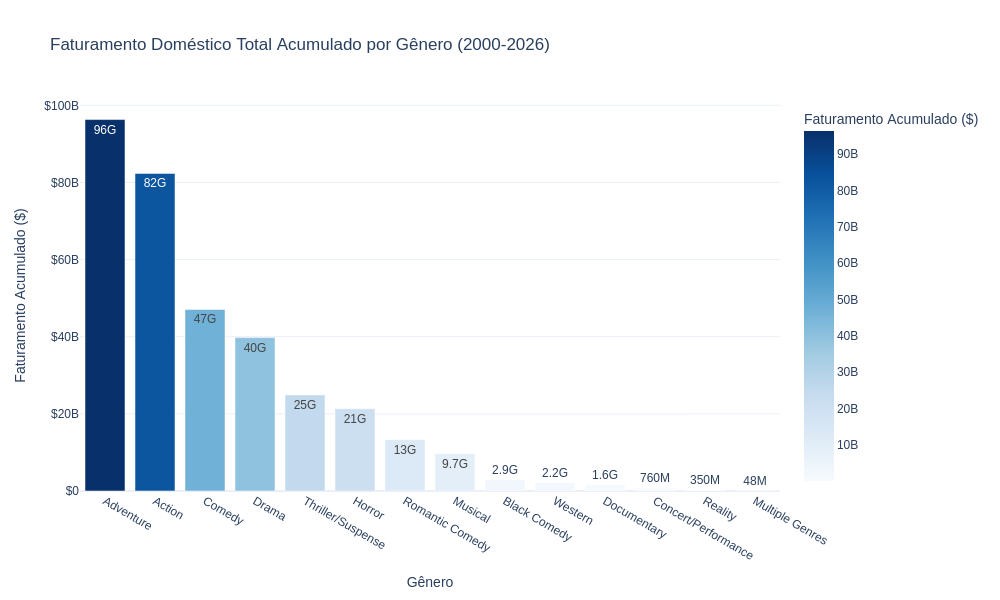

In [6]:
df_fat_total = df.groupby('genre')['domestic_bo'].sum().reset_index(name='faturamento_total')
df_fat_total = df_fat_total.sort_values(by='faturamento_total', ascending=False)

# 3. Cria o gráfico de barras
fig3 = px.bar(
    df_fat_total,
    x='genre',
    y='faturamento_total',
    color='faturamento_total',
    color_continuous_scale='Blues',
    title='Faturamento Doméstico Total Acumulado por Gênero (2000-2026)',
    labels={'genre': 'Gênero', 'faturamento_total': 'Faturamento Acumulado ($)'},
    text_auto='.2s'
)

fig3.update_layout(width=1000, height=600, template='plotly_white', showlegend=False)
fig3.update_yaxes(tickprefix='$', separatethousands=True)
fig3.show()

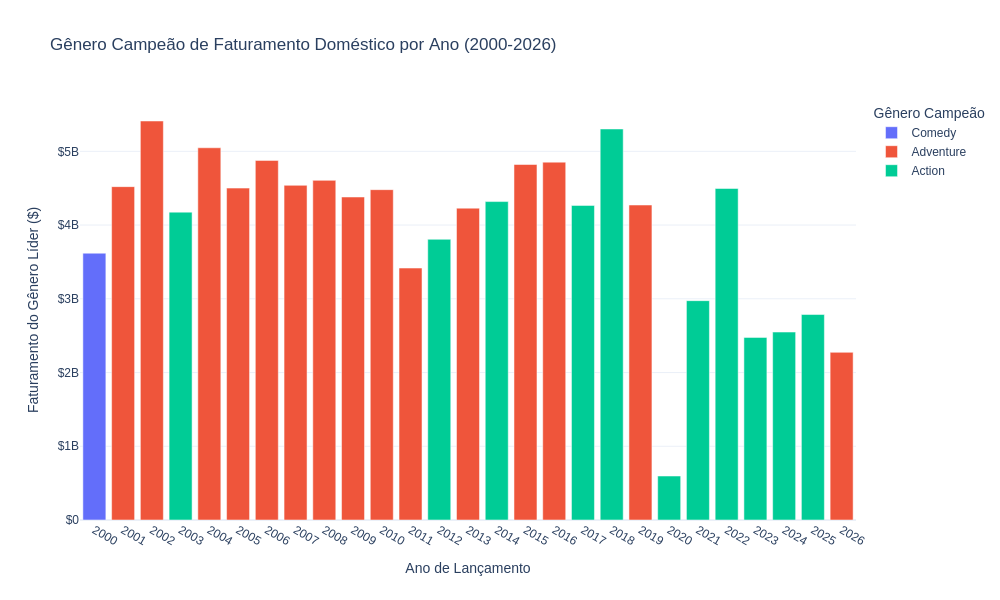

In [14]:
df_fat_ano = df.groupby(['year', 'genre'])['domestic_bo'].sum().reset_index()

# 3. Filtra apenas o gênero com o MAIOR faturamento para cada ano
idx_max = df_fat_ano.groupby('year')['domestic_bo'].idxmax()
df_top_genre = df_fat_ano.loc[idx_max].reset_index(drop=True)

# 4. Ordena estritamente por ano e converte para string (garante a ordem cronológica visual)
df_top_genre = df_top_genre.sort_values('year').reset_index(drop=True)
df_top_genre['year'] = df_top_genre['year'].astype(str)

# 5. Cria o gráfico de barras travando a ordem exata das categorias
fig = px.bar(
    df_top_genre,
    x='year',
    y='domestic_bo',
    color='genre',              # Cada gênero campeão ganha uma cor distinta na legenda
    title='Gênero Campeão de Faturamento Doméstico por Ano (2000-2026)',
    labels={
        'year': 'Ano de Lançamento', 
        'domestic_bo': 'Faturamento do Gênero Líder ($)',
        'genre': 'Gênero Campeão'
    },
    category_orders={'year': df_top_genre['year'].tolist()} # Força a ordem exata da lista
)

# 6. Ajustes visuais
fig.update_layout(
    width=1000, 
    height=600, 
    template='plotly_white'
)
fig.update_yaxes(tickprefix='$', separatethousands=True)

fig.show()

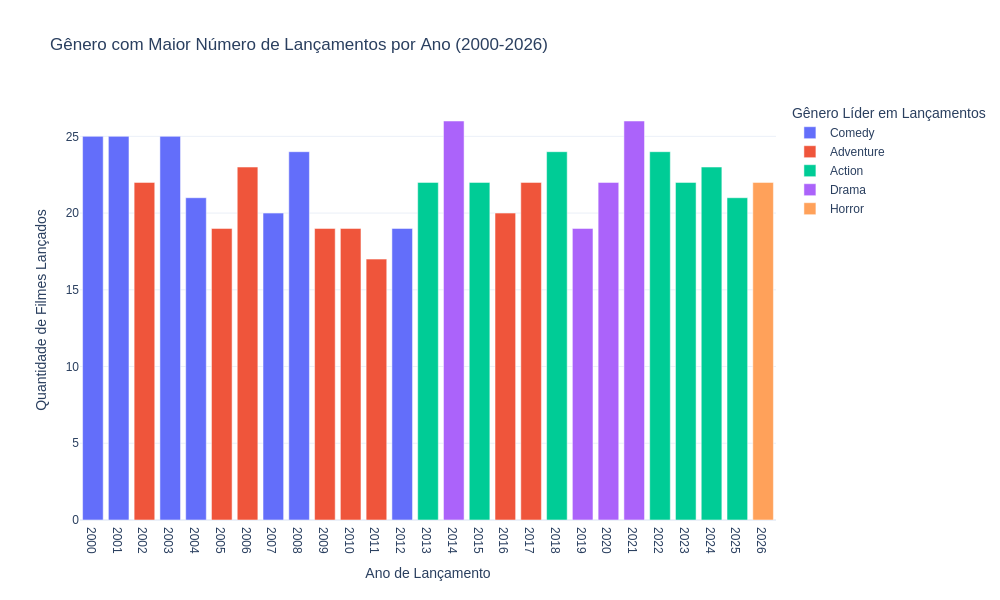

In [15]:
df_qtd_ano = df.groupby(['year', 'genre']).size().reset_index(name='quantidade_filmes')

# 3. Filtra apenas o gênero com o MAIOR número de lançamentos para cada ano
idx_max = df_qtd_ano.groupby('year')['quantidade_filmes'].idxmax()
df_top_lances = df_qtd_ano.loc[idx_max].reset_index(drop=True)

# 4. Ordena estritamente por ano e converte para string (garante a ordem cronológica correta)
df_top_lances = df_top_lances.sort_values('year').reset_index(drop=True)
df_top_lances['year'] = df_top_lances['year'].astype(str)

# 5. Cria o gráfico de barras travando a ordem exata das categorias
fig = px.bar(
    df_top_lances,
    x='year',
    y='quantidade_filmes',
    color='genre',              # Cada gênero campeão ganha uma cor distinta na legenda
    title='Gênero com Maior Número de Lançamentos por Ano (2000-2026)',
    labels={
        'year': 'Ano de Lançamento', 
        'quantidade_filmes': 'Quantidade de Filmes Lançados',
        'genre': 'Gênero Líder em Lançamentos'
    },
    category_orders={'year': df_top_lances['year'].tolist()} # Força a ordem cronológica
)

# 6. Ajustes visuais
fig.update_layout(
    width=1000, 
    height=600, 
    template='plotly_white'
)

fig.show()

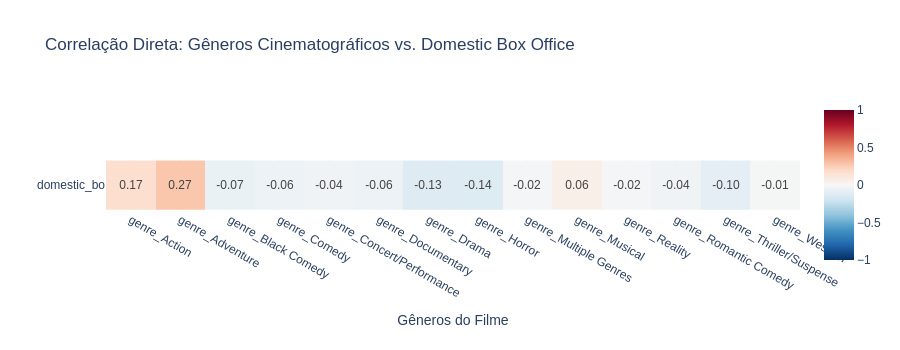

In [16]:
# 2. Transforma o gênero em colunas binárias (One-Hot Encoding) se a coluna existir
if 'genre' in df.columns:
    df_encoded = pd.get_dummies(df, columns=['genre'], drop_first=False, dtype=int)
else:
    df_encoded = df.copy()

# 3. Seleciona apenas as colunas numéricas globais
df_numerico = df_encoded.select_dtypes(include=[np.number])

# 4. Calcula a matriz de correlação completa
matriz_corr = df_numerico.corr()

# 5. Filtra a matriz para manter APENAS 'domestic_bo' e as colunas iniciadas com 'genre_'
colunas_genero = [col for col in matriz_corr.columns if col.startswith('genre_')]

if 'domestic_bo' in matriz_corr.columns and colunas_genero:
    # Cria uma matriz reduzida contendo apenas domestic_bo x gêneros
    matriz_focada = matriz_corr.loc[['domestic_bo'], colunas_genero]

    # 6. Gera o Heatmap focado com Plotly
    fig = px.imshow(
        matriz_focada,
        text_auto='.2f',
        color_continuous_scale='RdBu_r',
        zmin=-1, zmax=1,
        title='Correlação Direta: Gêneros Cinematográficos vs. Domestic Box Office'
    )

    fig.update_layout(
        width=900,
        height=350,  # Altura reduzida já que é uma matriz de uma linha só
        template='plotly_white',
        xaxis_title='Gêneros do Filme',
        yaxis_title=''
    )

    fig.show()
else:
    print("Aviso: As colunas 'domestic_bo' ou os gêneros codificados não foram encontrados no DataFrame.")